In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Load source file and final result list

In [ ]:
final_results = pd.read_excel('sample_data/Flow_C2C-005_results_final.xlsx', keep_default_na=False)

In [3]:
# add relative intensity
final_results['rel. Height'] = final_results['Height'] / final_results['Height'].sum() * 100
final_results['corr Resp'] = final_results['Height'] / final_results['Cnum_Final'] #corrects response by carbon number for FID signal normalisation
final_results['rel corr Resp'] = final_results['corr Resp'] / final_results['corr Resp'].sum() * 100
final_results.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z),LRI,DBE,CNum (RT),PI,N,A,Class,Cnum_Final,Class_Final,rel. Height,corr Resp,rel corr Resp
0,9.5858,9.57,2.15,26802,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9,812,0,8,221.60,38.48,33.92,PI,9,PI,0.179659,2978.000000,0.238897
1,9.7208,9.70,2.25,13021,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9,816,-1,-1,209.52,112.85,62.40,PI,9,PI,0.087282,1446.777778,0.116061
2,10.0542,10.03,2.25,82421,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9,825,0,8,191.22,33.01,8.88,PI,9,PI,0.552485,9157.888889,0.734651
3,11.0592,11.03,2.55,11428,7,65.0:8.58 66.2:9.76 67.15:14.01 67.2:26.67 69....,141.00,10,854,-1,-1,220.66,66.06,10.51,PI,10,PI,0.076604,1142.800000,0.091676
4,11.1900,11.17,2.40,165575,6,69.15:14.88 70.15:17.24 71.1:9.45 71.15:100.0 ...,127.20,9,858,0,9,174.18,21.51,0.00,PI,9,PI,1.109884,18397.222222,1.475835


In [4]:
labels_dict = dict({'PI': '(Iso)paraffins',
                    'N': 'Naphthenes',
                    'A': 'Aromatics',
                    'UN': 'Unsaturated Naphthenes',
                    'O': 'Olefins',
                    'PAH': 'Polyaromatic Hydrocarbon',
                    'X': 'Unknown'
                    })

sample_name = 'C2C-005'

column_name_carbon_number = 'Cnum_Final'
column_name_class = 'Class_Final'

In [5]:
class_group = final_results.groupby(by=column_name_class)
cnum_group = final_results.groupby(by=column_name_carbon_number)

In [6]:
colors = {
    'PI': '#e84035', #Paraffin/Isoparaffin
    'N': '#5fa381', #Naphthene
    'O': '#004c93', #Olefin
    'O/N': '#c2d33e', #Olefin/Naphthene with same score
    'UN': '#feca00', #Unsaturated Naphthene (DBE = 2)
    'A': '#782f88', #Aromatic
    'PAH': '#a68eca', #Polycyclic Aromatic Hydrocarbon (DBE >= 5)
    'X': '#a9a9a9' #Unknown, MS and GCxGC info not matching any class
}

### Grouped by CNUM and stacked

#### !!! CHANGE NAME OF PLOT FIRST !!!

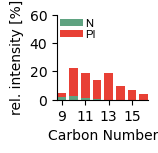

          N     PI  Total
9      1.66   3.35   5.01
10     2.42  19.87  22.29
11     1.03  18.16  19.18
12     0.45  13.70  14.15
13     0.14  18.54  18.69
14     0.07   9.42   9.49
15     0.00   6.85   6.85
16     0.00   4.33   4.33
Total  5.77  94.22  99.99


In [ ]:
rslt_name = 'flowmod_C2C005' #Platform+Sample

# grouped by carbon number and stacked

cm = 1/2.54 # inch to cm

classes = [cl[0] for cl in class_group]
cnum = [n[0] for n in cnum_group]
inty_sum = [0.0] * len(cnum)

intensity_dict = dict()

for cl in classes:
    intensity_dict[cl] = [0.0] * len(cnum)

for i, cn in enumerate(cnum):
    # get group
    df = cnum_group.get_group(cn)
    inty_sum[i] = round(df['rel corr Resp'].sum(), ndigits=2) 

    for cl in classes:
        sub_df = df[df[column_name_class]==cl]
        intensity_dict[cl][i] = round(sub_df['rel corr Resp'].sum(), ndigits=2)

#xlabs = [str(cn) + ' ('+ str(inty_sum[i])  + ' %)' for i, cn in enumerate(cnum)]
xlabs = [str(cn) for cn in cnum]
x = np.arange(len(cnum))*2  # the label locations
width = 1.5  # the width of the bars

#cmap = plt.colormaps.get_cmap('tab10')
#ci = 0
bottom = np.zeros(len(cnum))

fig, ax = plt.subplots(figsize=(4.125*cm, 4*cm))
#figsize=(8*cm, 6*cm) for 2x2 Figure in Report
#figsize=(4.125*cm, 4*cm) for x4 figure in Nat Commun

plt.rcParams.update({
    "font.size": 8, #10 for report, 8 for publication
    "axes.labelsize": 8, #10 for report, 6 for publication
    "axes.titlesize": 8, #10 for report, 8 for publication
    "xtick.labelsize": 6, #10 for report, 8 for publication
    "ytick.labelsize": 6, #10 for report, 8 for publication
    "legend.fontsize": 8, #10 for report, 8 for publication
    "figure.titlesize": 8, #10 for report, 8 for publication
    "font.family": "Arial"
})

for cl, inty in intensity_dict.items():
    rects = ax.bar(x, inty, width, label=cl, facecolor=colors.get(cl, '#a9a9a9'), bottom=bottom)
    labs = [''] * len(rects)
    for i in range(len(rects)):
        if rects[i].get_height() != 0.0:
            labs[i] = str(round(rects[i].get_height(), ndigits=2))
        else:
            labs[i] = ''
    #ax.bar_label(rects, labels=labs, padding=3, rotation=45, label_type='center')
    bottom += inty
    #ci += 1

ax.set_ylabel('rel. intensity [%]')
ax.set_xticks(x[::2], xlabs[::2], rotation=0)
ax.set_ylim(None, 60)
ax.legend(title='Class', ncols=3)
ax.legend(
    loc='upper left',
    frameon=False,
    facecolor='white',
    edgecolor='black',
    borderpad=0.2,      # padding inside legend border
    labelspacing=0.1,   # vertical space between entries
    handletextpad=0.2,  # space between line/marker and text
    borderaxespad=0.1   # space between legend and axes edge
)
ax.margins(x=0.005)
ax.set_xlabel('Carbon Number')

ax.spines['top'].set_visible(False) #only for nat commun plots
ax.spines['right'].set_visible(False) #only for nat commun plots

#ax.set_title(sample_name)

plt.tight_layout()

plt.savefig(f"{rslt_name}_Quant_cnum-group_class-stack.png", dpi=1200)
plt.show()

df_export = pd.DataFrame(intensity_dict, index=cnum)
df_export['Total'] = inty_sum
df_export.loc['Total'] = df_export.sum(axis=0)
print(df_export)
df_export.to_csv(f"{rslt_name}_Quant.csv", sep=',', index=False)